In [43]:
import pandas as pd
data = pd.read_csv("heart_failure_clinical_records_dataset.csv")
data.head()
print("Dataset Shape:", data.shape, "\n")

data.columns
data.info()

missing = data.isnull().sum()
print ("\n Total of missing value is:", missing.sum())

features_columns = ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time' ]

target_column = "DEATH_EVENT"

X = data[features_columns]
Y = data[target_column]
counts = Y.value_counts()


from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state= 42, stratify= Y, test_size= 0.2 )


Dataset Shape: (299, 13) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage:

              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000                299.000000  299.000000   
mean    60.833893    0.431438                581.839465    0.418060   
std     11.894809    0.496107                970.287881    0.494067   
min     40.000000    0.000000                 23.000000    0.000000   
25%     51.000000    0.000000                116.500000    0.000000   
50%     60.000000    0.000000                250.000000    0.000000   
75%     70.000000    1.000000                582.000000    1.000000   
max     95.000000    1.000000               7861.000000    1.000000   

       ejection_fraction  high_blood_pressure      platelets  \
count         299.000000           299.000000     299.000000   
mean           38.083612             0.351171  263358.029264   
std            11.834841             0.478136   97804.236869   
min            14.000000             0.000000   25100.000000   
25%            30.000000             0.0

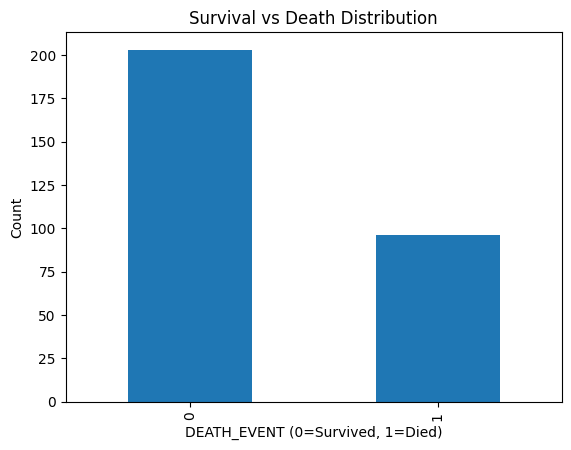

Target Distribution:
 DEATH_EVENT
0    203
1     96
Name: count, dtype: int64 





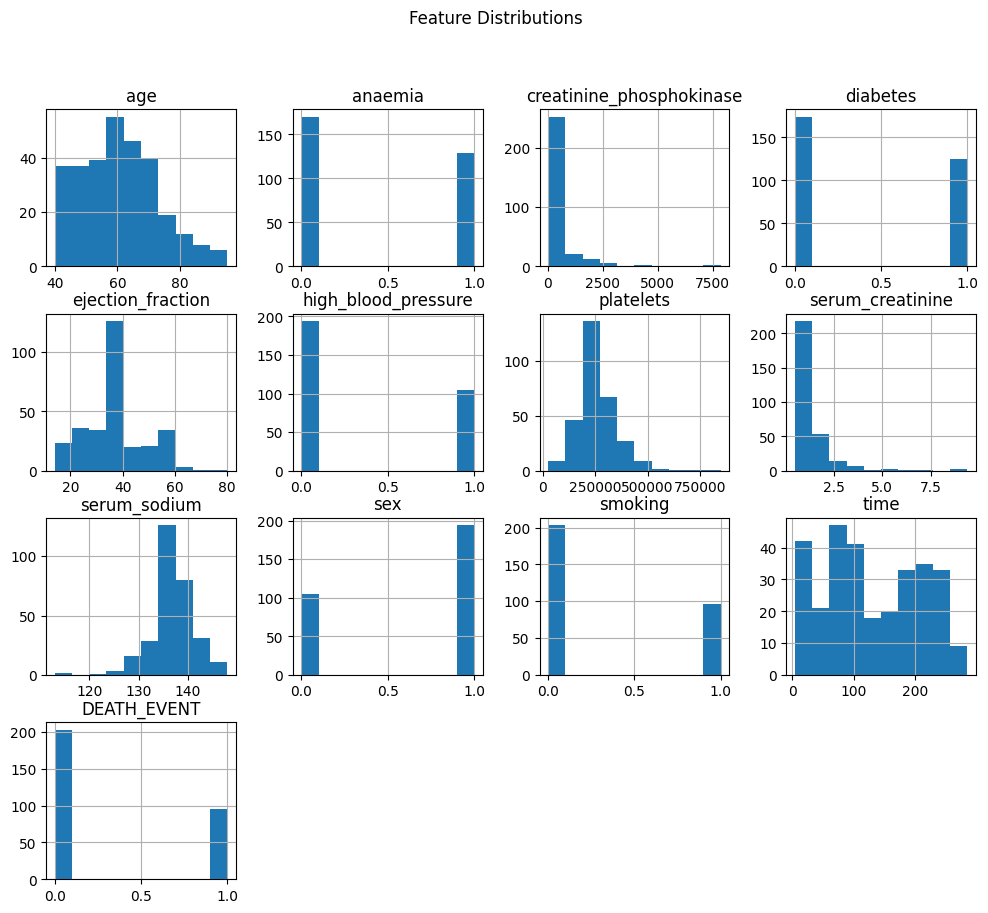

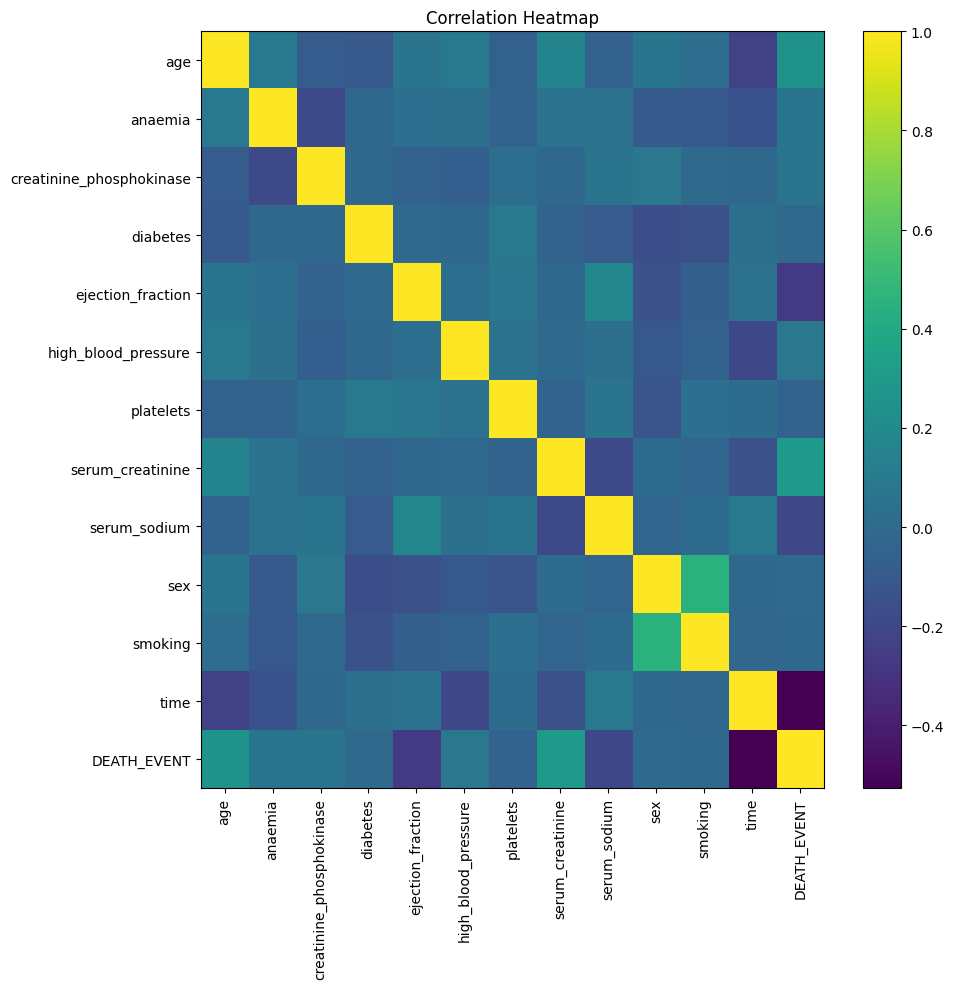

In [44]:
import matplotlib.pyplot as plt

print(data.describe(), "\n\n")

counts.plot(kind= "bar")
plt.title("Survival vs Death Distribution")
plt.xlabel("DEATH_EVENT (0=Survived, 1=Died)")
plt.ylabel("Count")
plt.show()
print("Target Distribution:\n", counts, "\n\n\n")


data.hist(figsize= (12, 10))
plt.suptitle("Feature Distributions")
plt.show()
print("\n\n")


corr = data.corr()
plt.figure(figsize=(10, 10))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation= 90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


Logistic Regression:

Accuracy:  0.8 

Classification Report: 

              precision    recall  f1-score   support

           0       0.82      0.90      0.86        41
           1       0.73      0.58      0.65        19

    accuracy                           0.80        60
   macro avg       0.78      0.74      0.75        60
weighted avg       0.79      0.80      0.79        60
 


Confusion Matrix:
 [[37  4]
 [ 8 11]] 



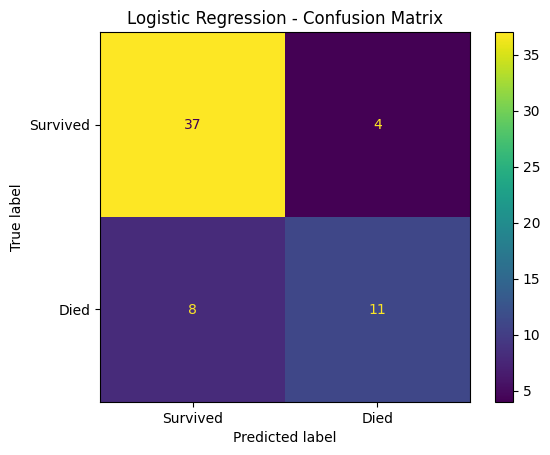





KNN:

Accuracy:  0.7 

Classification Report: 

              precision    recall  f1-score   support

           0       0.72      0.93      0.81        41
           1       0.57      0.21      0.31        19

    accuracy                           0.70        60
   macro avg       0.64      0.57      0.56        60
weighted avg       0.67      0.70      0.65        60
 


Confusion Matrix:
 [[38  3]
 [15  4]] 



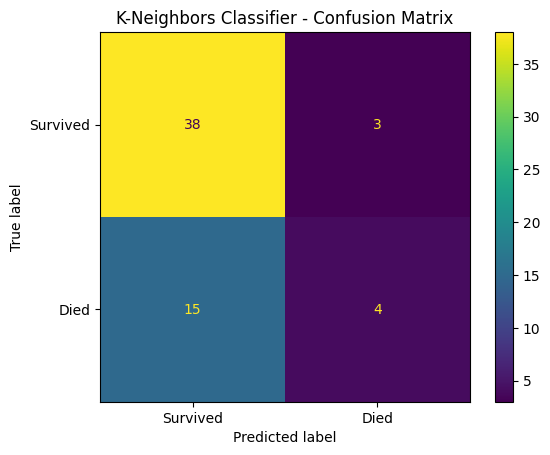

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay as cmd, f1_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


log_model = LogisticRegression(max_iter= 1000, class_weight= "balanced", random_state= 42)
log_pipe = Pipeline([ ("scaler", StandardScaler()), ("model", log_model) ])
log_pipe.fit(X_train, Y_train)

Y_log_prediction = log_pipe.predict(X_test)


print("Logistic Regression:\n")
print("Accuracy: ", accuracy_score(Y_test, Y_log_prediction), "\n")
print("Classification Report: \n")
print(classification_report(Y_test, Y_log_prediction), "\n\n")
print ("Confusion Matrix:\n", confusion_matrix(Y_test, Y_log_prediction), "\n")
cmd.from_predictions(Y_test, Y_log_prediction, display_labels= ["Survived", "Died"])
plt.title("Logistic Regression - Confusion Matrix")
plt.show()
print("\n\n\n")




from sklearn.neighbors import KNeighborsClassifier

KNN_model = KNeighborsClassifier(n_neighbors= 5)
KNN_pipe = Pipeline([ ("scaler", StandardScaler()), ("model", KNN_model)])
KNN_pipe.fit(X_train, Y_train)
Y_KNN_prediction = KNN_pipe.predict(X_test)

print("KNN:\n")
print("Accuracy: ", accuracy_score(Y_test, Y_KNN_prediction), "\n")
print("Classification Report: \n")
print(classification_report(Y_test, Y_KNN_prediction),"\n\n")
print ("Confusion Matrix:\n", confusion_matrix(Y_test, Y_KNN_prediction), "\n")
cmd.from_predictions(Y_test, Y_KNN_prediction, display_labels= ["Survived", "Died"])
plt.title("K-Neighbors Classifier - Confusion Matrix")
plt.show()


Decision Tree Classifier:

Accuracy:  0.75 

Classification Report: 

              precision    recall  f1-score   support

           0       0.77      0.90      0.83        41
           1       0.67      0.42      0.52        19

    accuracy                           0.75        60
   macro avg       0.72      0.66      0.67        60
weighted avg       0.74      0.75      0.73        60
 



Confusion Matrix:
 [[37  4]
 [11  8]] 



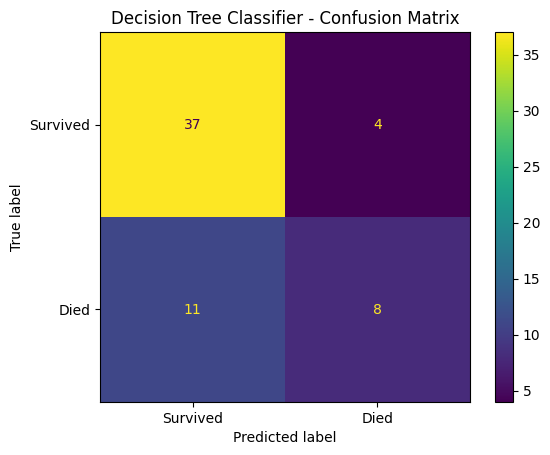





Random Forest Classifier:

Accuracy:  0.85 

Classification Report: 

              precision    recall  f1-score   support

           0       0.85      0.95      0.90        41
           1       0.86      0.63      0.73        19

    accuracy                           0.85        60
   macro avg       0.85      0.79      0.81        60
weighted avg       0.85      0.85      0.84        60
 


Confusion Matrix:
 [[39  2]
 [ 7 12]] 



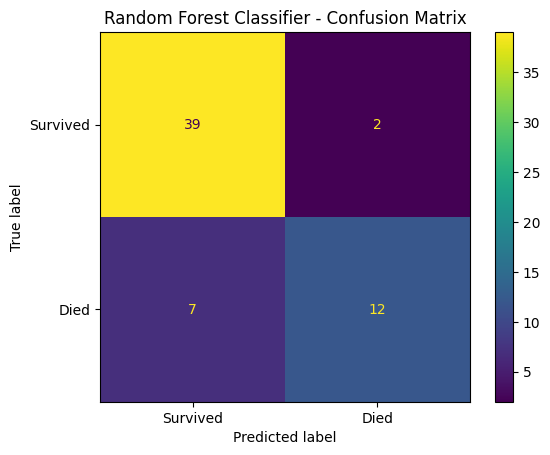

In [46]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier ( random_state= 42, max_depth= 4)
tree_pipe = Pipeline([("scaler", "passthrough"), ("model", tree_model)])
tree_pipe.fit(X_train, Y_train)
Y_tree_prediction = tree_pipe.predict(X_test)

print("Decision Tree Classifier:\n")
print("Accuracy: ", accuracy_score(Y_test, Y_tree_prediction), "\n")
print("Classification Report: \n")
print(classification_report(Y_test, Y_tree_prediction),"\n\n\n")
print("Confusion Matrix:\n", confusion_matrix(Y_test, Y_tree_prediction), "\n")
cmd.from_predictions(Y_test, Y_tree_prediction, display_labels= ["Survived", "Died"])
plt.title("Decision Tree Classifier - Confusion Matrix")
plt.show()
print("\n\n\n")




from sklearn.ensemble import RandomForestClassifier

RF_model = RandomForestClassifier (random_state= 42, class_weight= "balanced", max_depth= 6, n_estimators= 200)
RF_pipe = Pipeline([("scaler", "passthrough"), ("model", RF_model)])
RF_pipe.fit(X_train, Y_train)
Y_RF_prediction = RF_pipe.predict(X_test)

print("Random Forest Classifier:\n")
print("Accuracy: ", accuracy_score(Y_test, Y_RF_prediction), "\n")
print("Classification Report: \n")
print(classification_report(Y_test, Y_RF_prediction),"\n\n")
print("Confusion Matrix:\n", confusion_matrix(Y_test, Y_RF_prediction), "\n")
cmd.from_predictions(Y_test, Y_RF_prediction, display_labels= ["Survived", "Died"])
plt.title("Random Forest Classifier - Confusion Matrix")
plt.show()


In [47]:
model_comp = pd.DataFrame.from_dict ({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "KNN"],

    "Accuracy": [
        accuracy_score(Y_test, Y_log_prediction),
        accuracy_score(Y_test, Y_tree_prediction ),
        accuracy_score(Y_test, Y_RF_prediction),
        accuracy_score(Y_test, Y_KNN_prediction )
        ],

    "Recall": [
        recall_score(Y_test, Y_log_prediction),
        recall_score(Y_test, Y_tree_prediction),
        recall_score(Y_test, Y_RF_prediction),
        recall_score(Y_test, Y_KNN_prediction)
        ],

    "F1-score": [
        f1_score(Y_test, Y_log_prediction),
        f1_score(Y_test, Y_tree_prediction),
        f1_score(Y_test, Y_RF_prediction),
        f1_score(Y_test, Y_KNN_prediction)
        ]
})
model_comp

,Model,Accuracy,Recall,F1-score
0,Logistic Regression,0.80,0.578947,0.647059
1,Decision Tree,0.75,0.421053,0.516129
2,Random Forest,0.85,0.631579,0.727273
3,KNN,0.70,0.210526,0.307692


Best parameters:  {'model__max_depth': 3, 'model__n_estimators': 100} 

Best CV F1: 0.7841273648484275 

Tuned Random Forest Accuracy:

Accuracy:  0.85 

F1:  0.7428571428571429 

Recall:  0.6842105263157895 

Classification Report: 

              precision    recall  f1-score   support

           0       0.86      0.93      0.89        41
           1       0.81      0.68      0.74        19

    accuracy                           0.85        60
   macro avg       0.84      0.81      0.82        60
weighted avg       0.85      0.85      0.85        60
 


Confusion Matrix:  [[38  3]
 [ 6 13]] 



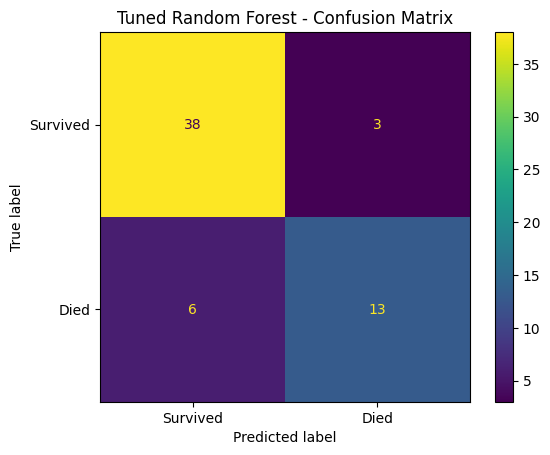

In [48]:
from sklearn.model_selection import GridSearchCV

RF_initial = RandomForestClassifier (random_state= 42, class_weight= "balanced")
GS_RF_pipe = Pipeline([ ("scaler", "passthrough"), ("model", RF_initial)])

param_grid = {
    "model__n_estimators": [100, 200, 300 ],
    "model__max_depth": [3, 4, 5, 6, 7, None]
}

grid_search = GridSearchCV (estimator= GS_RF_pipe, param_grid= param_grid, cv= 5, scoring= "f1", n_jobs= -1)
grid_search.fit(X_train, Y_train)

best_RF = grid_search.best_estimator_
Y_best_RF_prediction = best_RF.predict(X_test)

print("Best parameters: ", grid_search.best_params_, "\n")
print("Best CV F1:", grid_search.best_score_,"\n")
print("Tuned Random Forest Accuracy:\n")
print("Accuracy: ", accuracy_score(Y_test, Y_best_RF_prediction), "\n")
print("F1: ", f1_score(Y_test, Y_best_RF_prediction),"\n")
print("Recall: ", recall_score(Y_test, Y_best_RF_prediction),"\n")
print("Classification Report: \n")
print(classification_report(Y_test, Y_best_RF_prediction),"\n\n")
print("Confusion Matrix: ", confusion_matrix(Y_test, Y_best_RF_prediction), "\n")
cmd.from_predictions(Y_test, Y_best_RF_prediction, display_labels= ["Survived", "Died"])
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()


In [49]:
from sklearn.model_selection import cross_val_score

print("\n Overfitting / Underfitting Check:\n")

train_f1 = f1_score(Y_train, best_RF.predict(X_train))
test_f1 = f1_score(Y_test, Y_best_RF_prediction)

print("Train F1: ", train_f1, "\n")
print("Test F1: ", test_f1, "\n")


cv_scores = cross_val_score(best_RF, X_train, Y_train, cv= 5, scoring= "f1")

print("CV F1 Mean: ", cv_scores.mean(), "\n")
print("CV F1 Std: ", cv_scores.std(), "\n")


 Overfitting / Underfitting Check:

Train F1:  0.8607594936708861 

Test F1:  0.7428571428571429 

CV F1 Mean:  0.7841273648484275 

CV F1 Std:  0.08269827099433044 



Voting Classifier:

Voting Accuracy: 0.7833333333333333 

F1:  0.5806451612903226 

Recall:  0.47368421052631576 

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.93      0.85        41
           1       0.75      0.47      0.58        19

    accuracy                           0.78        60
   macro avg       0.77      0.70      0.72        60
weighted avg       0.78      0.78      0.77        60
 


Confusion Matrix:
 [[38  3]
 [10  9]] 



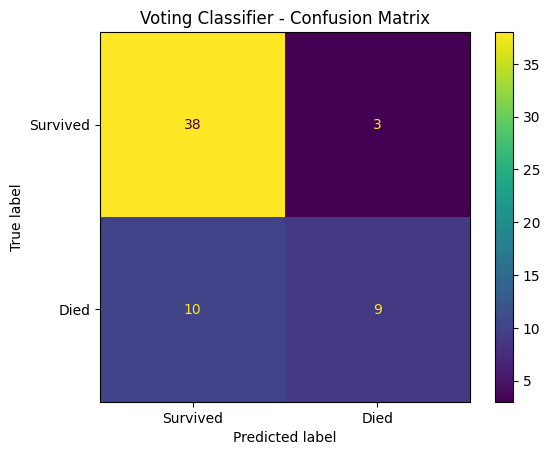

In [50]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier (
    estimators = [
        ("Logistic Regression", log_pipe),
        ("KNN", KNN_pipe),
        ("Decision Tree", tree_pipe),
        ("Random Forest", best_RF) ],

    voting= "hard"
)


voting_model.fit(X_train, Y_train)

Y_voting_prediction = voting_model.predict(X_test)

print("Voting Classifier:\n")
print("Voting Accuracy:", accuracy_score(Y_test, Y_voting_prediction), "\n")
print("F1: ", f1_score(Y_test, Y_voting_prediction),"\n")
print("Recall: ", recall_score(Y_test, Y_voting_prediction),"\n")
print("Classification Report:\n")
print(classification_report(Y_test, Y_voting_prediction), "\n\n")
print("Confusion Matrix:\n", confusion_matrix(Y_test, Y_voting_prediction), "\n")
cmd.from_predictions(Y_test, Y_voting_prediction, display_labels= ["Survived", "Died"])
plt.title("Voting Classifier - Confusion Matrix")
plt.show()


In [51]:
model_accuracy_table = pd.DataFrame.from_dict ({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "KNN","Tuned Random Forest", "Voting Classifier" ],

    "Accuracy": [
        accuracy_score(Y_test, Y_log_prediction),
        accuracy_score(Y_test, Y_tree_prediction ),
        accuracy_score(Y_test, Y_RF_prediction),
        accuracy_score(Y_test, Y_KNN_prediction ),
        accuracy_score(Y_test, Y_best_RF_prediction),
        accuracy_score(Y_test, Y_voting_prediction)
        ],

    "Recall": [
        recall_score(Y_test, Y_log_prediction),
        recall_score(Y_test, Y_tree_prediction),
        recall_score(Y_test, Y_RF_prediction),
        recall_score(Y_test, Y_KNN_prediction),
        recall_score(Y_test, Y_best_RF_prediction),
        recall_score(Y_test, Y_voting_prediction)
        ],

    "F1-score": [
        f1_score(Y_test, Y_log_prediction),
        f1_score(Y_test, Y_tree_prediction),
        f1_score(Y_test, Y_RF_prediction),
        f1_score(Y_test, Y_KNN_prediction),
        f1_score(Y_test, Y_best_RF_prediction),
        f1_score(Y_test, Y_voting_prediction)
        ]

})
model_accuracy_table


,Model,Accuracy,Recall,F1-score
0,Logistic Regression,0.800000,0.578947,0.647059
1,Decision Tree,0.750000,0.421053,0.516129
2,Random Forest,0.850000,0.631579,0.727273
3,KNN,0.700000,0.210526,0.307692
4,Tuned Random Forest,0.850000,0.684211,0.742857
5,Voting Classifier,0.783333,0.473684,0.580645
